
# **Word embeddings za klasifikaciju dokumenata (recenzija)**

Ovaj notebook ilustruje klasifikaciju teksta uz pomoc unapred obucenog modela za ugnjezdavanje reci [GloVe](https://nlp.stanford.edu/projects/glove/) radi transformacije tekstualnih podataka u numericke vektore (koji sluze kao ulaz za algoritme klasifikacije).

U ovom primeru se koristi isti skup podataka kao i do sada.

### Inicijalno podesavanje: preuzimanje potrebnih modela, ucitavanje paketa, podesavanje nekih korisnih promenljivih
Do sada je koriscen spaCy-jev najmanji pipeline za engleski jezik (_en_core_web_sm_) - obezbedjuje recnik, sintaksu i entitete, ali **ne i vektore**.
Kako bismo iskoristili prednosti spaCy-jevog ugradjenog modela za vektore reci, bice nam potreban veci pipeline, i to ili `en_core_web_md` ili `en_core_web_lg`.

Koristicemo srednji model, ali je preporuka da na svom racunaru preuzmete i radite sa velikim (_en_core_web_lg_). Da biste ga preuzeli, pokrenite sledecu liniju u Terminalu ili Command Prompt-u:

`python -m spacy download en_core_web_lg`

In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split, GridSearchCV

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.preprocessing import RobustScaler
from sklearn.compose import ColumnTransformer

# moduli za prekomerno uzorkovanje (oversampling) i izgradnju pipeline-a
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

from sklearn import metrics
from sklearn.metrics import ConfusionMatrixDisplay

# sklearn moduli koji implementiraju algoritme klasifikacije
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

import spacy
from pathlib import Path

RAND_STATE = 1

# spacy pipeline za pretprocesiranje teksta i vektore reci
SPACY_MODEL = "en_core_web_md"


### Istrazimo spaCy-jev unapred obuceni model za vektore reci (GloVe)

Ucitavanje spaCy pipeline-a sa unapred obucenim GloVe vektorima reci

In [2]:
spacy_model = spacy.load(SPACY_MODEL, disable=['parser','ner'])

Zbog razlike izmedju broja reci (685 000) i broja jedinstvenih vektora (20 000) u ucitanom NLP pipeline-u, da bi se smanjila velicina modela, **spacy mapira nekoliko blisko povezanih reci na isti vektor**; na primer, reci kao sto su 'kid', 'kids', 'child', 'children' sve bi bile mapirane na isti vektor.

Evo kako izgleda vektorska reprezentacija reci:

In [3]:
world_vec = spacy_model('world').vector

# rec "world" prolazi kroz ucitani spaCy model, koji tekst pretvara u objekat koji u sebi sadrzi gomilu lingvistickih podataka o toj reci

# .vector uzima predefinisani vektor reci za tu rec
# vektor je niz brojeva koji predstavlja "znacenje" reci u visedimenzionalnom prostoru
# reci sa slicnim znacenjem (npr. "world", "earth", "planet") imace vektore koji su blizu jedan drugom u tom prostoru

In [4]:
print(f"Vectors dimension: {len(world_vec)}")

# duzina vektora = broj elemenata u nizu
# znaci da je rec "world" opisana pomocu 300 razlicitih numerickih karakteristika

Vectors dimension: 300


In [5]:
print('World: ', world_vec)

World:  [-6.2752e-01  9.6647e-02  5.8525e-02 -4.1364e-02  8.2091e-03  1.2230e-01
 -3.7158e-01  1.1244e+00 -1.0964e-01  2.6778e+00  4.9412e-01 -3.1716e-01
 -7.4560e-02  3.4692e-01 -6.0170e-02  1.4428e-01 -4.0906e-01  3.7426e-01
 -1.8449e-01  1.6487e-01 -5.5287e-01 -1.4136e-01  2.9449e-01  4.7711e-01
  6.8386e-01 -4.7221e-02  7.1285e-01  3.0253e-01 -4.0780e-01  7.1487e-01
 -4.2733e-01  9.5346e-02 -4.8627e-01  1.4888e-01  4.4621e-01 -1.5371e-01
 -1.9430e-01 -1.4995e-01  2.8414e-02  5.7656e-01  1.2100e-02  1.5328e-04
 -7.4318e-02  4.7869e-01  3.0866e-02 -7.0779e-01 -7.7787e-02  5.5496e-01
 -2.1231e-01 -2.1367e-01  2.2433e-01 -1.6196e-01 -1.4790e-01 -1.7868e-01
  3.0867e-01 -1.4638e-01 -8.8241e-02 -4.4340e-02  2.9901e-01 -4.9765e-01
 -1.8245e-01 -3.5274e-01  9.0349e-02 -1.0826e+00 -1.7650e-01 -3.2504e-01
 -5.2780e-01 -3.9316e-01 -4.3747e-01 -3.0031e-01  9.5930e-02 -4.8797e-02
 -2.6289e-02 -2.2738e-01 -1.4851e-02  2.5013e-01 -3.0001e-01 -1.9170e-01
  4.4040e-01  1.9953e-01 -3.2057e-01  4.680


### Slicnost reci

Kada su reci predstavljene kao vektori, mozemo da koristimo linearnu algebru i modele vektorskog prostora da bismo analizirali odnos izmedju reci.

Prvo cemo ispitati slicnosti reci, racunanjem **_kosinusne slicnosti (cosine similarity)_** vektora reci.
Kosinusna slicnost je siroko koriscena mera semanticke slicnosti reci. Njena vrednost se krece od `-1` do `1`, iako se obicno koristi u ne-negativnom prostoru `[0, 1]` gde 0 znaci `odsustvo slicnosti`, a 1 znaci `ekstremno slicno ili identicno`.

Kosinusna slicnost je implementirana u spacy-jevoj funkciji `similarity`.

In [6]:
dog = spacy_model('dog')
cat = spacy_model('cat')
computer = spacy_model('computer')
software = spacy_model('software')

print(f"Similarity of dog and cat: {dog.similarity(cat)}")
print(f"Similarity of dog and computer: {dog.similarity(computer)}")
print(f"Similarity of computer and software: {computer.similarity(software)}")

Similarity of dog and cat: 1.0000001192092896
Similarity of dog and computer: 0.07917961478233337
Similarity of computer and software: 0.9999999403953552



### Vizuelizacija Word Embeddings-a

Vizuelizacija se cesto koristi da bi se bolje razumelo kako vektori reci modeliraju odnose izmedju reci.

Posto su vektori reci visoko-dimenzionalni – GloVe ima 300 dimenzija, a noviji modeli imaju nekoliko hiljada dimenzija – nije moguca direktna vizuelizacija.

Tipican pristup za prevazilazenje tog izazova je **primena algoritma za smanjenje dimenzionalnosti** (`dimensionality reduction`) i `vizuelizacija tako transformisanih podataka`. Sledeci put cemo koristiti t-SNE, popularnu tehniku za smanjenje dimenzionalnosti, kako bismo smanjili vektore reci na 2D i istrazili odnose izmedju reci da vidimo mozemo li vizuelno da pronadjemo neki sablon.
Za sada, istrazicemo interaktivnu vizuelizaciju embedding-a reci koja se moze naci ovde: https://projector.tensorflow.org/


# Koriscenje embedding-a reci za klasifikaciju teksta

## Ucitavanje i priprema podataka

Koristimo skup podataka (dataset) sa recenzijama mobilnih aplikacija.

In [9]:
data_file_path = Path.cwd() / 'data' / 'mobile_apps_reviews.csv'

In [10]:
data = pd.read_csv(data_file_path)
data.head()

,id,app,version,rating,date,device,user,review,category
0,1,com.androtiyas.dragonvirtual,1.08,5,1387756426967,?,Alexis Gonzalez,cute!!!! the game is just to cute!!!! :3,OTHER
1,2,com.androtiyas.dragonvirtual,1.1,4,1390090741168,Galaxy Precedent,A Google User,? well its ok but not bad nor is it great,OTHER
2,3,com.androtiyas.dragonvirtual,?,1,1387746296815,Toshiba AT100,Reyna We,? have no idea how to feed dragon and boooorrr...,OTHER
3,4,com.androtiyas.dragonvirtual,1.06,2,1386518193950,?,mariah harris,when i play games it reboots about every third...,BUG
4,5,com.androtiyas.dragonvirtual,1.06,5,1386915595583,?,Wren Brown,love my dragon have fun! yahoooey! godbless,OTHER


Ponovo kreiramo izlaznu varijablu na isti nacin, tacnije:

* functional: BUG, FEATURE
* non-functional: PERFORMANCE, USABILITY, ENERGY, SECURITY
* other: OTHER

In [11]:
def category_to_cls(cat):
  if cat == "OTHER": return cat
  if cat in ['BUG', 'FEATURE']: return "FUNCTIONAL"
  return "NON-FUNCTIONAL"

data['cls'] = data.category.apply(category_to_cls)
data.cls.value_counts(normalize=True)

cls
OTHER             0.501667
FUNCTIONAL        0.365667
NON-FUNCTIONAL    0.132667
Name: proportion, dtype: float64

Dodajemo kolonu **_review_len_** i zadrzavamo _review, review_len_ i _rating_ (kao pre), a zatim delimo skup podataka na train i test.

In [12]:
data['review_len'] = data.review.apply(len)

X = data[['review','review_len','rating']]
y = data['cls']

y_encodings, y_levels = pd.factorize(y)

X_train, X_test, y_train, y_test = train_test_split(X, y_encodings, test_size = 0.2, random_state = RAND_STATE, stratify=y)


### Koriscenje embedding-a (ugradjivanja) reci za reprezentaciju dokumenata

Postoji nacin da numericki predstavimo svaku rec – _embeddings_ obezbedjuju vektor za svaku rec u nasem recniku.

Medjutim, da bismo uradili klasifikaciju, potrebna nam je **numericka reprezentacija _kompletnih_ recenzija (dokumenata)**.

Dakle, za svaku recenziju nam je potreban vektor koji bi predstavljao tu recenziju, a taj vektor bi trebalo da bude zasnovan na embedding-zima reci koje se nalaze u toj recenziji.

Postoji nekoliko opcija da se to uradi; ovde primenjujemo veoma jednostavan metod: **racunamo prosek embedding-a reci koje cine recenziju**. Ovaj metod cesto dobro funkcionise za kratke tekstove kao sto su recenzije sa kojima radimo.


### Kreiranje sopstvene (custom) klase transformera

Kreiracemo klasu – `ReviewVectorizer` – koja transformise svaku recenziju u vektorsku reprezentaciju, kao sto je gore opisano, koristeci unapred obuceni (pre-trained) GloVe model (integrisan u spaCy NLP pipeline).

Ovoj transformaciji prethodi svodjenje teksta na reci koje nose semantiku, tako da se samo _najvaznije_ reci koriste za izgradnju reprezentacije teksta (recenzije).

Imajte na umu da je klasa ReviewVectorizer definisana kao potklasa sklearn-ovih klasa `BaseEstimator` i `TransformerMixin`.

Ovo je neophodno kako bi nasa komponenta transformera bila kompatibilna sa sklearn-ovim alatima kao sto su `GridSearchCV` i `Pipeline`.

Konkretno, n**asledjivanjem klase `TransformerMixin`, nasa klasa postaje sklearn-ov Transformer i samim tim stice pravo da bude ukljucena u Pipeline**.

Da bismo omogucili podesavanje sopstvenih parametara (atributa) za nas transformer preko Pipeline-a, takodje moramo da nasledimo `**BaseEstimator**`, jer ce nam to obezbediti metode `set_param` i `get_param` koje sluze za postavljanje i dohvatanje parametara (atributa) transformera tokom izvrsavanja koda (runtime).
Kada kreiramo sopstveni transformer nasledjivanjem klasa BaseEstimator i TransformerMixin, prvenstveno smo **u obavezi da implementiramo sledece metode**:

`__init__(self, *args, **kwargs)` - uloga metode __init__ je da inicijalizuje transformator.
**Vazno:** svi atributi naseg prilagodjenog transformatora koje korisnik moze da podesi moraju biti definisani kao ulazni argumenti metode __init__ i sacuvani kao atributi instance.

`fit(self, X, y=None)` - da nauci sve potrebne parametre iz podataka za treniranje; za transformator, ovo obicno ukljucuje izracunavanje statistika kao sto su srednja vrednost ili standardna devijacija. Mora da vrati self.

`transform(self, X)` - da primeni transformaciju na ulazne podatke, tj. X, koristeci parametre naucene u fit metodi. Mora da vrati transformisane podatke.

In [13]:
class ReviewVectorizer(BaseEstimator, TransformerMixin):

    def __init__(self, spacy_pipeline, vector_dim=300):

        # NLP pipeline koji se koristi
        self.spacy_pipeline = spacy_pipeline
        # dimenzionalnost vektora
        self.vector_dim = vector_dim

    def spacy_tokenizer(self, doc):

        tokens = self.spacy_pipeline(doc)

        tokens = [token for token in tokens
                  if ((not token.is_punct) and
                      (not token.like_num) and
                      (not token.like_url) and
                      (not token.is_space) and
                      (not token.is_stop))]

        words = [token.lemma_.lower() for token in tokens]

        return words


    def fit(self, X, y=None):
        return self


    def transform(self, X):

        # kreiranje nula-matrice
        # broj redova = broj dokumenata
        # broj kolona = dimenzije spacy-jevih vektora reci

        X_transformed = np.zeros((len(X), self.vector_dim))

        for i, text in enumerate(X):
            words = self.spacy_tokenizer(text)

            # dobijanje vektora za svaki komentar racunanjem proseka vektora izabranih reci - onih koje nose znacenje
            X_transformed[i] = self.spacy_pipeline(" ".join(words)).vector

        return X_transformed


### Treniranje klasifikatora na embedding-zima dokumenata

* `ReviewVectorizer` - transformisanje recenzija u vektore pomocu modela za word embeddings
* `RobustScaler` - skaliranje dve dodatne karakteristike (koristeci medijanu i interkvartilni opseg) tako da sve karakteristike budu u priblizno jednakom opsegu vrednosti

Nakon toga, mozemo koristiti dobijeni skup karakteristika za izgradnju klasifikatora.

In [14]:
# ucitavanje modela potrebnih za ReviewVectorizer, ako vec nisu ucitani
# spacy_model = spacy.load(SPACY_MODEL)

# instanciranje vectorizer-a recenzija
vectorizer = ReviewVectorizer(spacy_pipeline=spacy_model)

# instanciranje transformera za skaliranje druge dve karakteristike (rating i review_len)
scaler = RobustScaler()

# primena transformera na sve kolone
column_transformer = ColumnTransformer(
    transformers=[
        ('embeddings', vectorizer, 'review'),
        ('scaling', scaler, ['review_len','rating']),
        ])

Koristicemo logisticku regresiju (**Logistic Regression**) kao **klasifikator**, jer su klasifikatori zasnovani na linearnoj granici pogodni za vektorski prostor koji formiraju gusti (embedding) vektori.

Takodje koristimo **SMOTE metod uzorkovanja** (resampling) kako bismo resili problem **_neizbalansiranog_** skupa podataka (setite se da tri kategorije recenzija (klase) nisu podjednako zastupljene).

SMOTE je skracenica od Synthetic Minority Oversampling Technique (Tehnika generisanja sintetickih uzoraka manjinske klase) i to je tehnika za **povecanje velicine manjinske klase** (i samim tim balansiranje distribucije klasa) sintetizovanjem **novih** instanci te klase iz postojecih instanci.
Ukratko, SMOTE radi na sledeci nacin:

Prvo se bira nasumicna instanca iz manjinske klase. Zatim se pronalazi **k najblizih komsija za tu instancu (obicno k=5)**. Bira se nasumicno selektovani komsija i kreira se sinteticka instanca u nasumicno izabranoj tacki izmedju te dve instance u prostoru karakteristika.

Na kraju, imajte na umu da koristimo Pipeline iz biblioteke `imblearn.pipeline` (ne iz sklearn.pipeline kao u prethodnim lekcijama), buduci da ova vrsta pipeline-a pravilno rukuje metodama za balansiranje klasa (primena  **`na skup za treniranje`**, ali ne i na skup za testiranje).

In [15]:
lr_classifier = LogisticRegression(random_state=RAND_STATE, max_iter=2000)

smote = SMOTE(random_state=RAND_STATE)

lr_pipe = Pipeline(
    [
        ('data_transform', column_transformer),
        ('resampling', smote),
        ('classifier', lr_classifier)
     ],
     verbose=True)

lr_pipe.fit(X_train, y_train)

[Pipeline] .... (step 1 of 3) Processing data_transform, total=  21.9s
[Pipeline] ........ (step 2 of 3) Processing resampling, total=   2.8s
[Pipeline] ........ (step 3 of 3) Processing classifier, total=   0.9s


,steps,"[('data_transform', ...), ('resampling', ...), ...]"
,transform_input,None
,memory,None
,verbose,True
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('embeddings', ...), ('scaling', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready fo

### Evaluacija pipeline-a

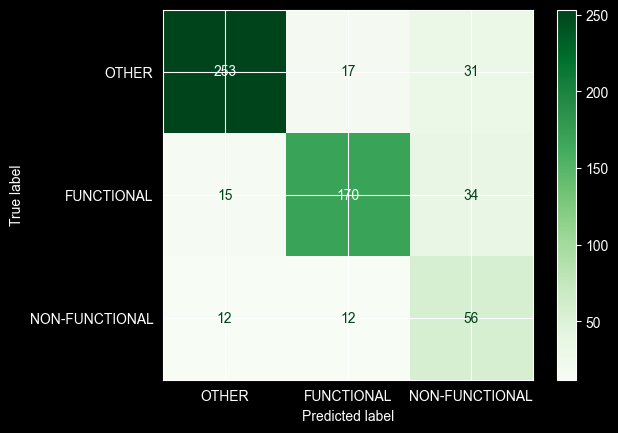

In [16]:
ConfusionMatrixDisplay.from_estimator(
        lr_pipe,
        X_test,
        y_test,
        display_labels=y_levels,
        cmap='Greens',
    );

In [17]:
lr_predictions = lr_pipe.predict(X_test)

print(metrics.classification_report(y_true = y_test, y_pred = lr_predictions))

              precision    recall  f1-score   support

           0       0.90      0.84      0.87       301
           1       0.85      0.78      0.81       219
           2       0.46      0.70      0.56        80

    accuracy                           0.80       600
   macro avg       0.74      0.77      0.75       600
weighted avg       0.83      0.80      0.81       600



In [18]:
bacc_lr = metrics.balanced_accuracy_score(y_test, lr_predictions)
print(f"Balanced accuracy: {bacc_lr:0.4f}")

Balanced accuracy: 0.7723


Ovo nije mnogo bolje od performansi koje smo imali sa BoW (Bag-of-Words) modelom. Fine-tuning pipeline-a bi mogao da poboljsa rezultate – isprobajte sami.

Istrazicemo da li drugi algoritam klasifikacije – onaj koji se cesto koristi u klasifikaciji teksta – moze dovesti do boljih performansi.


### Kreiranje i evaluacija SVM klasifikatora


Ovog puta koristicemo Support Vector Machines (SVM) klasifikator.

Ovaj tip klasifikatora se pokazao uspesnim u zadacima klasifikacije teksta; generalno je poznat po tome sto dobro rukuje visoko-dimenzionalnim podacima (kao sto je ovde slucaj).
 Takodje dobro funkcionise sa (relativno) malim skupovima podataka.

Koristicemo najjednostavniju verziju ovog klasifikatora, a to je SVM sa linearnim kernelom (odnosno, linearnom transformacijom originalnih karakteristika).

Ovaj tip klasifikatora se moze implementirati pomocu sklearn-ove SVC klase sa 'linear' kernelom.

In [19]:
svm_classifier = SVC(kernel='linear',
                     C=1, # default vrednost hiperparametra
                     random_state=RAND_STATE,
                     decision_function_shape='ovo')

svm_pipe = Pipeline(
    [
        ('data_transform', column_transformer),
        ('resampling', smote),
        ('classifier', svm_classifier)
     ],
     verbose=True
)

svm_pipe.fit(X_train, y_train)

[Pipeline] .... (step 1 of 3) Processing data_transform, total=  24.9s
[Pipeline] ........ (step 2 of 3) Processing resampling, total=   0.1s
[Pipeline] ........ (step 3 of 3) Processing classifier, total=   2.3s


,steps,"[('data_transform', ...), ('resampling', ...), ...]"
,transform_input,None
,memory,None
,verbose,True
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('embeddings', ...), ('scaling', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready fo

Pravimo predvidjanja na test skupu i izracunavamo mere evaluacije.

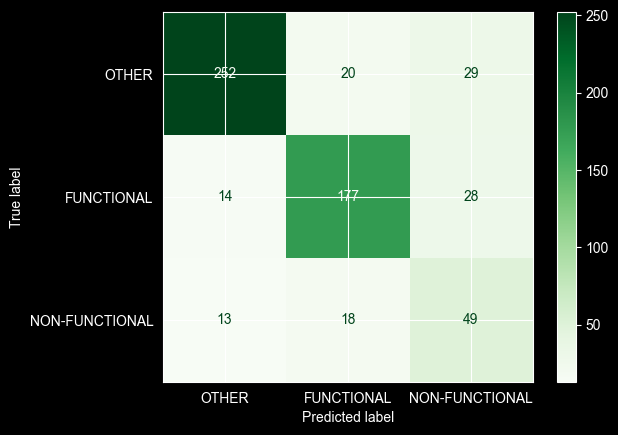

In [20]:
ConfusionMatrixDisplay.from_estimator(svm_pipe, X_test, y_test, display_labels=y_levels, cmap='Greens');

In [21]:
svm_predictions = svm_pipe.predict(X_test)

print(metrics.classification_report(y_test, svm_predictions, target_names=y_levels))

                precision    recall  f1-score   support

         OTHER       0.90      0.84      0.87       301
    FUNCTIONAL       0.82      0.81      0.82       219
NON-FUNCTIONAL       0.46      0.61      0.53        80

      accuracy                           0.80       600
     macro avg       0.73      0.75      0.74       600
  weighted avg       0.82      0.80      0.80       600



In [22]:
bacc_svm = metrics.balanced_accuracy_score(y_test, svm_predictions)
print(f"Balanced accuracy: {bacc_svm:0.4f}" )

Balanced accuracy: 0.7526


Pogledajmo kako se izvode predvidjanja:

In [23]:
# funkcija odlucivanja (decision function) primenjena na prvu instancu iz skupa za treniranje
print(svm_pipe.decision_function(X_train[:1]))

[[-1.26791702 -1.61881097 -1.78029238]]


Ova tri rezultata poticu od tri one-vs-one klasifikatora:
* 0 (Other) vs 1 (Functional)
* 0 (Other) vs 2 (Non-Functional)
* 1 (Functional) vs 2 (Non-Functional)

Svaki rezultat je ishod linearne funkcije (kao u linearnoj regresiji):
z = b + w * X,

gde je:

* x jedna tacka podataka: lista vrednosti karakteristika (features)
* w je vektor tezina (weight vector): jedna po karakteristici; moze se dobiti preko `clf.coef_`
* b je pomeraj (bias/intercept): jedan broj; moze se dobiti pomocu `clf.intercept_`

Negativna vrednost oznacava dodeljivanje negativnoj klasi, a pozitivna vrednost oznacava dodeljivanje pozitivnoj klasi.

Dakle, u nasem slucaju, rezultati se mogu interpretirati na sledeci nacin:


* -1.26791702 => 1 (Functional)
* -1.61881097 => 2 (Non-Functional)
* -1.78029238 => 2 (Non-Functional)

Klasa 2 (Non-Functional) dobija 2 glasa => instanci se dodeljuje klasa 2. To mozemo i da proverimo:

In [24]:
print(svm_pipe.predict(X_train[:1]))

[2]


### Poboljsanje SVM modela kroz podesavanje hiperparametara (hyperparameter tuning)

Mozemo da probamo da poboljsamo model klasifikacije kroz podesavanje hiperparametara.

Konkretno, ispitacemo opseg vrednosti za hiperparametar **C**.

Ovim hiperparametrom odredjujemo **koliko zelimo da kaznimo pogresno klasifikovane tacke** – sto je **veca** vrednost C, to je **veca** kazna, ali je i **veci rizik** od preteranog prilagodjavanja (**_overfitting_**).

Podesavanje cemo uraditi pomocu grid search-a preko navedenog opsega vrednosti parametra C.

Podsetnik: za GridSearchCV, imena hiperparametara moraju da imaju **prefiks sa imenom klasifikatora kako je zadato u pipeline-u**;

u ovom slucaju, ime je `classifier`, tako da hiperparametar C dobija prefiks `classifier__`.

In [25]:
%%time

param_grid = dict(classifier__C=[0.01, 0.1, 1, 10, 100])
grid_search = GridSearchCV(svm_pipe,
                           param_grid=param_grid,
                           scoring='f1_macro',
                           verbose=2)

# grid_search.set_params(classifier__max_iter=5000) # u slucaju da tuning potraje, postavite granicu na broj iteracija za konvergenciju algoritma

grid_search.fit(X_train, y_train)

# Wall time: 14min 44s

Fitting 5 folds for each of 5 candidates, totalling 25 fits
[Pipeline] .... (step 1 of 3) Processing data_transform, total=  24.7s
[Pipeline] ........ (step 2 of 3) Processing resampling, total=   0.3s
[Pipeline] ........ (step 3 of 3) Processing classifier, total=   2.2s
[CV] END .................................classifier__C=0.01; total time=  33.2s
[Pipeline] .... (step 1 of 3) Processing data_transform, total=  24.0s
[Pipeline] ........ (step 2 of 3) Processing resampling, total=   0.3s
[Pipeline] ........ (step 3 of 3) Processing classifier, total=   1.0s
[CV] END .................................classifier__C=0.01; total time=  28.5s
[Pipeline] .... (step 1 of 3) Processing data_transform, total=  17.6s
[Pipeline] ........ (step 2 of 3) Processing resampling, total=   0.0s
[Pipeline] ........ (step 3 of 3) Processing classifier, total=   0.9s
[CV] END .................................classifier__C=0.01; total time=  21.9s
[Pipeline] .... (step 1 of 3) Processing data_transform, t

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step... verbose=True)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__C': [0.01, 0.1, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1_macro'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",None
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidate is displayed;- >2 : the score is also displayed;- >3 : the fold an

In [26]:
print('best parameters: ', grid_search.best_params_)
print('best scores: ', grid_search.best_score_)

best parameters:  {'classifier__C': 0.1}
best scores:  0.7418635132761782


Ponovno treniranje SVM klasifikatora pomocu optimalne vrednosti parametra C

In [27]:
best_c = grid_search.best_params_['classifier__C']
svm_pipe.set_params(classifier__C=best_c)
svm_pipe.fit(X_train,y_train)

[Pipeline] .... (step 1 of 3) Processing data_transform, total=  23.6s
[Pipeline] ........ (step 2 of 3) Processing resampling, total=   0.1s
[Pipeline] ........ (step 3 of 3) Processing classifier, total=   1.3s


,steps,"[('data_transform', ...), ('resampling', ...), ...]"
,transform_input,None
,memory,None
,verbose,True
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('embeddings', ...), ('scaling', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready fo

Evaluacija optimizovanog modela

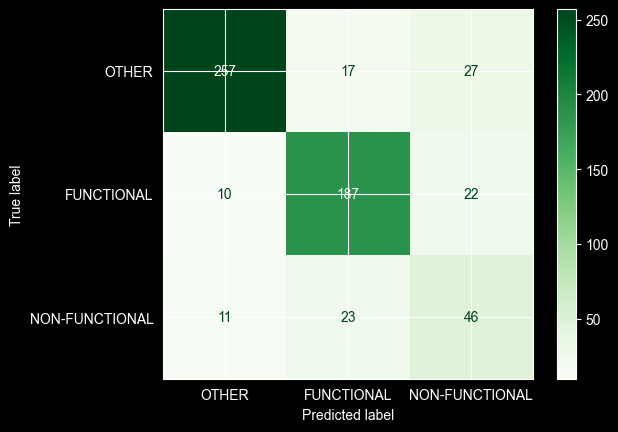

In [28]:
ConfusionMatrixDisplay.from_estimator(svm_pipe, X_test, y_test, display_labels=y_levels, cmap='Greens');

In [29]:
svm_opt_predictions = svm_pipe.predict(X_test)

print(metrics.classification_report(y_test, svm_opt_predictions, target_names=y_levels))

                precision    recall  f1-score   support

         OTHER       0.92      0.85      0.89       301
    FUNCTIONAL       0.82      0.85      0.84       219
NON-FUNCTIONAL       0.48      0.57      0.53        80

      accuracy                           0.82       600
     macro avg       0.74      0.76      0.75       600
  weighted avg       0.83      0.82      0.82       600



In [30]:
bacc_svm_opt = metrics.balanced_accuracy_score(y_test, svm_opt_predictions)
print(f"Balanced accuracy: {bacc_svm_opt:0.4f}" )

Balanced accuracy: 0.7609



### Poredjenje svih modela

Pomocna funkcija za izdvajanje mera evaluacije iz funkcije `metrics.classification_report`:

In [31]:
def get_model_metrics(y_true, y_pred, model_name):

    # izracunaj P, R, F1
    report = metrics.classification_report(y_true, y_pred, output_dict=True)

    # izracunaj balanced accuracy
    b_acc = metrics.balanced_accuracy_score(y_true, y_pred)

    # izdvoj metrike i za makro i za tezinski prosek (macro i weighted averages)
    macro_avg = report['macro avg']
    weighted_avg = report['weighted avg']

    # kreiraj recnik sa rezultatima
    results = {
        'Model': model_name,
        'Macro Precision': macro_avg['precision'],
        'Macro Recall': macro_avg['recall'],
        'Macro F1-Score': macro_avg['f1-score'],
        'Weighted Precision': weighted_avg['precision'],
        'Weighted Recall': weighted_avg['recall'],
        'Weighted F1-Score': weighted_avg['f1-score'],
        'Balanced Accuracy': b_acc
    }

    return results

Kreiranje laznog klasifikatora (dummy classifier), koji ce sluziti kao opsta pocetna tacka za poredjenje (baseline).

In [32]:
from sklearn.dummy import DummyClassifier

dummy_clf = DummyClassifier(strategy='stratified')
# generise predvidjanja postujuci distribuciju klasa iz skupa za treniranje

dummy_clf.fit(X_train, y_train)
dummy_pred = dummy_clf.predict(X_test)

Poredjenje svih modela koriscenjem gore definisane pomocne funkcije `get_model_metrics`

In [33]:
model_predictions = {
    'W2V_LR': lr_predictions,
    'W2V_LinSVM': svm_predictions,
    'W2V_OptLinSVM': svm_opt_predictions,
    'DUMMY': dummy_pred
}

all_results = list()

for model_name, model_pred in model_predictions.items():
  model_res = get_model_metrics(y_test, model_pred, model_name)
  all_results.append(model_res)

all_results_df = pd.DataFrame(all_results)
all_results_df.set_index("Model", inplace=True)
all_results_df = all_results_df.apply(lambda x: round(x, 4))

print("Model Performance Comparison:")
print(all_results_df)

Model Performance Comparison:
               Macro Precision  Macro Recall  Macro F1-Score  \
Model                                                          
W2V_LR                  0.7402        0.7723          0.7472   
W2V_LinSVM              0.7296        0.7526          0.7372   
W2V_OptLinSVM           0.7442        0.7609          0.7507   
DUMMY                   0.3300        0.3276          0.3284   

               Weighted Precision  Weighted Recall  Weighted F1-Score  \
Model                                                                   
W2V_LR                     0.8268           0.7983             0.8081   
W2V_LinSVM                 0.8152           0.7967             0.8039   
W2V_OptLinSVM              0.8290           0.8167             0.8215   
DUMMY                      0.4061           0.4017             0.4036   

               Balanced Accuracy  
Model                             
W2V_LR                    0.7723  
W2V_LinSVM                0.7526  
W2V_Op